In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import importlib
import pathlib
import sys

sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import data
import contract
import features

In [37]:

importlib.reload(features)

# Load a fresh copy of the original CSV.
raw_df = data.read_raw()

# Take a snapshot before preparation.
raw_snapshot = raw_df.copy(deep=True)

# Prepare the data.
prepared_df = features.prepare_bookings(raw_df)

print("========== CORRECTED VALIDATION ==========")

print("Raw dataset shape:", raw_df.shape)
print("Prepared dataset shape:", prepared_df.shape)

# Compare original data against its snapshot.
print("\nOriginal DataFrame unchanged:", raw_df.equals(raw_snapshot))

# Verify row preservation.
print("Rows preserved:", len(raw_df) == len(prepared_df))

# Verify missing values.
print("\nMissing values after cleaning:")
print(prepared_df[["children", "country", "agent", "company"]].isnull().sum())

# Verify duplicates are retained.
print("\nDuplicate records retained:")
print(prepared_df.duplicated().sum())

# Verify scoring columns.
print("\nScoring columns available:", all(col in prepared_df.columns for col in features.SCORING_COLUMNS))

========== CORRECTED VALIDATION ==========
Raw dataset shape: (119390, 32)
Prepared dataset shape: (118563, 34)

Original DataFrame unchanged: True
Rows preserved: False

Missing values after cleaning:
children    0
country     0
agent       0
company     0
dtype: int64

Duplicate records retained:
31926

Scoring columns available: True


In [38]:
# Build the prepared dataset through the approved feature pipeline.
import data
import features

raw_df = data.read_raw()
df = features.prepare_bookings(raw_df)


In [39]:
import importlib
import features

importlib.reload(features)
# Check the approved feature list
print("Number of model features:", len(features.MODEL_FEATURES))
print("\nApproved model features:")
print(features.get_feature_columns(df))
print("\nTarget variable:")
print(features.TARGET)
print("\nScoring columns:")
print(features.SCORING_COLUMNS)

Number of model features: 9

Approved model features:
['hotel', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'company', 'customer_type']

Target variable:
is_canceled

Scoring columns:
['hotel', 'arrival_date', 'is_canceled', 'adr', 'nights']


In [40]:


raw = data.read_raw()
bookings = features.prepare_bookings(raw)

X, y, scoring = features.split_model_inputs(bookings)

train_scoring, choose_scoring, proof_scoring = contract.split_periods(scoring)

X_train = X.loc[train_scoring.index]
y_train = y.loc[train_scoring.index]

X_choose = X.loc[choose_scoring.index]
y_choose = y.loc[choose_scoring.index]

scoring_choose = choose_scoring[features.SCORING_COLUMNS]

In [41]:
# ============================================================
# STEP 4: CREATE TEMPORAL MODEL DATASETS
# ============================================================

# Use the official project split.
train_df, choose_df, proof_df = contract.split_periods(prepared_df)

# Separate model inputs, target and scoring data for each period.
X_train, y_train, score_train = features.split_model_inputs(train_df)
X_choose, y_choose, score_choose = features.split_model_inputs(choose_df)
X_proof, y_proof, score_proof = features.split_model_inputs(proof_df)

print("========== TEMPORAL MODEL DATASETS ==========")
print("\nTRAIN")
print("Features:", X_train.shape)
print("Target:", y_train.shape)
print("Scoring:", score_train.shape)
print("\nCHOOSE")
print("Features:", X_choose.shape)
print("Target:", y_choose.shape)
print("Scoring:", score_choose.shape)
print("\nPROOF")
print("Features:", X_proof.shape)
print("Target:", y_proof.shape)
print("Scoring:", score_proof.shape)
print("\nCancellation rates:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Choose:", round(y_choose.mean() * 100, 2), "%")
print("Proof:", round(y_proof.mean() * 100, 2), "%")
print("\nRow count validation:")
print(len(X_train) + len(X_choose) + len(X_proof) == len(prepared_df))
print("\nIndex alignment:")
print("Train:", X_train.index.equals(y_train.index))
print("Choose:", X_choose.index.equals(y_choose.index))
print("Proof:", X_proof.index.equals(y_proof.index))

========== TEMPORAL MODEL DATASETS ==========

TRAIN
Features: (48747, 9)
Target: (48747,)
Scoring: (48747, 5)

CHOOSE
Features: (29307, 9)
Target: (29307,)
Scoring: (29307, 5)

PROOF
Features: (40509, 9)
Target: (40509,)
Scoring: (40509, 5)

Cancellation rates:
Train: 36.03 %
Choose: 37.13 %
Proof: 38.83 %

Row count validation:
True

Index alignment:
Train: True
Choose: True
Proof: True


In [42]:
X_train

print("========== FEATURE DATA TYPES ==========")
print(X_train.dtypes)

print("\n========== NUMERIC FEATURES ==========")
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
print(numeric_features)

print("\n========== CATEGORICAL FEATURES ==========")
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print(categorical_features)

print("\n========== FEATURE COUNT ==========")
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("Total:", len(numeric_features) + len(categorical_features))
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify feature types explicitly
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["str", "object", "category", "bool"]).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(transformers=[
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", "passthrough", numeric_features),
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform later periods without fitting again
X_choose_processed = preprocessor.transform(X_choose)
X_proof_processed = preprocessor.transform(X_proof)

print("========== PREPROCESSING RESULTS ==========")
print("Train:", X_train_processed.shape)
print("Choose:", X_choose_processed.shape)
print("Proof:", X_proof_processed.shape)
print("\nFeature count after encoding:")
print(X_train_processed.shape[1])
print("\nSame feature dimensions across periods:")
print(X_train_processed.shape[1] == X_choose_processed.shape[1] == X_proof_processed.shape[1])
X_train
import numpy as np
from scipy import sparse

def check_processed_data(name, X, y):
    if sparse.issparse(X):
        has_missing = np.isnan(X.data).any()
        has_infinite = np.isinf(X.data).any()
    else:
        has_missing = np.isnan(X).any()
        has_infinite = np.isinf(X).any()
    print(f"\n{name}")
    print("Rows match target:", X.shape[0] == len(y))
    print("Missing values:", has_missing)
    print("Infinite values:", has_infinite)

check_processed_data("TRAIN", X_train_processed, y_train)
check_processed_data("CHOOSE", X_choose_processed, y_choose)
check_processed_data("PROOF", X_proof_processed, y_proof)
print("\nEncoder fitted:", hasattr(preprocessor, "transformers_"))
print("Number of categorical columns:", len(categorical_features))
X_train_processed

========== FEATURE DATA TYPES ==========
hotel                               str
market_segment                      str
distribution_channel                str
is_repeated_guest                 int64
previous_cancellations            int64
previous_bookings_not_canceled    int64
agent                               str
company                             str
customer_type                       str
dtype: object

========== NUMERIC FEATURES ==========
['is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled']

========== CATEGORICAL FEATURES ==========
['hotel', 'market_segment', 'distribution_channel', 'agent', 'company', 'customer_type']

========== FEATURE COUNT ==========
Numeric: 3
Categorical: 6
Total: 9


C:\Users\Divyanshi\AppData\Local\Temp\ipykernel_34892\3292312044.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


========== PREPROCESSING RESULTS ==========
Train: (48747, 454)
Choose: (29307, 454)
Proof: (40509, 454)

Feature count after encoding:
454

Same feature dimensions across periods:
True

TRAIN
Rows match target: True
Missing values: False
Infinite values: False

CHOOSE
Rows match target: True
Missing values: False
Infinite values: False

PROOF
Rows match target: True
Missing values: False
Infinite values: False

Encoder fitted: True
Number of categorical columns: 6


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 301104 stored elements and shape (48747, 454)>

In [43]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    brier_score_loss,
    f1_score
)

# Rank each model's transformed inputs and accumulate one cross-model table.
feature_names = preprocessor.get_feature_names_out()
feature_importance_parts = []

def record_feature_importance(model, model_name, importance_type):
    if hasattr(model, "coef_"):
        values = np.mean(np.abs(model.coef_), axis=0)
    else:
        values = model.feature_importances_
    model_importance = pd.DataFrame({
        "Model": model_name,
        "Feature": feature_names,
        "Importance": values,
        "Importance type": importance_type,
    }).sort_values("Importance", ascending=False).reset_index(drop=True)
    feature_importance_parts.append(model_importance)
    return model_importance

# Initialize baseline model
baseline_model = LogisticRegression(
    max_iter=500,
    class_weight="balanced",
    random_state=42
)

# Train using training data only
baseline_model.fit(X_train_processed, y_train)

# Predict cancellation probabilities
train_prob = baseline_model.predict_proba(X_train_processed)[:, 1]
choose_prob = baseline_model.predict_proba(X_choose_processed)[:, 1]

# Evaluate on choose period
choose_pred = (choose_prob >= 0.5).astype(int)

print("========== LOGISTIC REGRESSION BASELINE ==========")
print("Choose ROC-AUC:", round(roc_auc_score(y_choose, choose_prob), 4))
print("Choose Accuracy:", round(accuracy_score(y_choose, choose_pred), 4))
print("Choose Precision:", round(precision_score(y_choose, choose_pred), 4))
print("Choose Recall:", round(recall_score(y_choose, choose_pred), 4))
print("Choose Brier Score:", round(brier_score_loss(y_choose, choose_prob), 4))
logistic_importance_df = record_feature_importance(
    baseline_model, "Logistic Regression", "mean absolute coefficient"
)
feature_importance_df = pd.concat(feature_importance_parts, ignore_index=True)
print("\nTop Logistic Regression feature importance:")
display(logistic_importance_df.head(20))


========== LOGISTIC REGRESSION BASELINE ==========
Choose ROC-AUC: 0.7512
Choose Accuracy: 0.6792
Choose Precision: 0.5582
Choose Recall: 0.652
Choose Brier Score: 0.1884

Top Logistic Regression feature importance:


,Model,Feature,Importance,Importance type
0,Logistic Regression,categorical__agent_281.0,4.633028,mean absolute coefficient
1,Logistic Regression,numeric__previous_cancellations,3.607052,mean absolute coefficient
2,Logistic Regression,categorical__agent_236.0,3.559940,mean absolute coefficient
3,Logistic Regression,categorical__company_202.0,3.274009,mean absolute coefficient
4,Logistic Regression,categorical__agent_310.0,3.120235,mean absolute coefficient
5,Logistic Regression,categorical__agent_28.0,3.088063,mean absolute coefficient
6,Logistic Regression,categorical__company_72.0,2.864974,mean absolute coefficient
7,Logistic Regression,categorical__agent_74.0,2.683700,mean absolute coefficient
8,Logistic Regression,categorical__agent_27.0,2.579335,mean absolute coefficient
9,Logistic Regression,categorical__agent_162.0,2.557617,mean absolute coefficient


In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, brier_score_loss, f1_score, precision_score,
    recall_score, roc_auc_score,
)

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced",
    max_depth=8,
    min_samples_leaf=50,
)
decision_tree_model.fit(X_train_processed, y_train)
cancel_col = list(decision_tree_model.classes_).index(1)
choose_prob_dt = decision_tree_model.predict_proba(X_choose_processed)[:, cancel_col]
choose_pred_dt = (choose_prob_dt >= 0.5).astype(int)
print("========== DECISION TREE BASELINE ==========")
print("Choose ROC-AUC:", round(roc_auc_score(y_choose, choose_prob_dt), 4))
print("Choose Accuracy:", round(accuracy_score(y_choose, choose_pred_dt), 4))
print("Choose Precision:", round(precision_score(y_choose, choose_pred_dt, zero_division=0), 4))
print("Choose Recall:", round(recall_score(y_choose, choose_pred_dt, zero_division=0), 4))
print("Choose F1:", round(f1_score(y_choose, choose_pred_dt, zero_division=0), 4))
print("Choose Brier Score:", round(brier_score_loss(y_choose, choose_prob_dt), 4))
decision_tree_importance_df = record_feature_importance(
    decision_tree_model, "Decision Tree", "model feature_importances_"
)
feature_importance_df = pd.concat(feature_importance_parts, ignore_index=True)
print("\nTop Decision Tree feature importance:")
display(decision_tree_importance_df.head(20))


========== DECISION TREE BASELINE ==========
Choose ROC-AUC: 0.7328
Choose Accuracy: 0.6652
Choose Precision: 0.5415
Choose Recall: 0.6406
Choose F1: 0.5869
Choose Brier Score: 0.1943

Top Decision Tree feature importance:


,Model,Feature,Importance,Importance type
0,Decision Tree,numeric__previous_cancellations,0.459352,model feature_importances_
1,Decision Tree,categorical__market_segment_Groups,0.188331,model feature_importances_
2,Decision Tree,categorical__customer_type_Transient,0.063000,model feature_importances_
3,Decision Tree,categorical__distribution_channel_TA/TO,0.060754,model feature_importances_
4,Decision Tree,categorical__market_segment_Online TA,0.035867,model feature_importances_
5,Decision Tree,categorical__hotel_Resort Hotel,0.029537,model feature_importances_
6,Decision Tree,categorical__agent_9.0,0.024538,model feature_importances_
7,Decision Tree,categorical__agent_240.0,0.024401,model feature_importances_
8,Decision Tree,numeric__previous_bookings_not_canceled,0.023956,model feature_importances_
9,Decision Tree,categorical__agent_28.0,0.021775,model feature_importances_


In [45]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
random_forest_model.fit(X_train_processed, y_train)
cancel_col = list(random_forest_model.classes_).index(1)
choose_prob_rf = random_forest_model.predict_proba(X_choose_processed)[:, cancel_col]
choose_pred_rf = (choose_prob_rf >= 0.5).astype(int)
print("========== RANDOM FOREST BASELINE ==========")
print("Choose ROC-AUC:", round(roc_auc_score(y_choose, choose_prob_rf), 4))
print("Choose Accuracy:", round(accuracy_score(y_choose, choose_pred_rf), 4))
print("Choose Precision:", round(precision_score(y_choose, choose_pred_rf, zero_division=0), 4))
print("Choose Recall:", round(recall_score(y_choose, choose_pred_rf, zero_division=0), 4))
print("Choose F1:", round(f1_score(y_choose, choose_pred_rf, zero_division=0), 4))
print("Choose Brier Score:", round(brier_score_loss(y_choose, choose_prob_rf), 4))
random_forest_importance_df = record_feature_importance(
    random_forest_model, "Random Forest", "model feature_importances_"
)
feature_importance_df = pd.concat(feature_importance_parts, ignore_index=True)
print("\nTop Random Forest feature importance:")
display(random_forest_importance_df.head(20))


========== RANDOM FOREST BASELINE ==========
Choose ROC-AUC: 0.7264
Choose Accuracy: 0.6632
Choose Precision: 0.538
Choose Recall: 0.657
Choose F1: 0.5916
Choose Brier Score: 0.2128

Top Random Forest feature importance:


,Model,Feature,Importance,Importance type
0,Random Forest,numeric__previous_cancellations,0.251933,model feature_importances_
1,Random Forest,categorical__market_segment_Groups,0.123438,model feature_importances_
2,Random Forest,categorical__agent_1.0,0.074260,model feature_importances_
3,Random Forest,categorical__hotel_City Hotel,0.053566,model feature_importances_
4,Random Forest,categorical__hotel_Resort Hotel,0.046130,model feature_importances_
5,Random Forest,categorical__distribution_channel_TA/TO,0.043674,model feature_importances_
6,Random Forest,categorical__customer_type_Transient-Party,0.038829,model feature_importances_
7,Random Forest,categorical__customer_type_Transient,0.036045,model feature_importances_
8,Random Forest,categorical__market_segment_Direct,0.032788,model feature_importances_
9,Random Forest,categorical__distribution_channel_Direct,0.030624,model feature_importances_


In [46]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, brier_score_loss, f1_score, precision_score, recall_score, roc_auc_score

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train_processed, y_train)
cancel_col = list(xgb_model.classes_).index(1)
choose_prob_xgb = xgb_model.predict_proba(X_choose_processed)[:, cancel_col]
choose_pred_xgb = (choose_prob_xgb >= 0.5).astype(int)
print("========== XGBOOST BASELINE ==========")
print("Choose ROC-AUC:", round(roc_auc_score(y_choose, choose_prob_xgb), 4))
print("Choose Accuracy:", round(accuracy_score(y_choose, choose_pred_xgb), 4))
print("Choose Precision:", round(precision_score(y_choose, choose_pred_xgb, zero_division=0), 4))
print("Choose Recall:", round(recall_score(y_choose, choose_pred_xgb, zero_division=0), 4))
print("Choose F1:", round(f1_score(y_choose, choose_pred_xgb, zero_division=0), 4))
print("Choose Brier Score:", round(brier_score_loss(y_choose, choose_prob_xgb), 4))
xgboost_importance_df = record_feature_importance(
    xgb_model, "XGBoost", "model feature_importances_"
)
feature_importance_df = pd.concat(feature_importance_parts, ignore_index=True)
print("\nTop XGBoost feature importance:")
display(xgboost_importance_df.head(20))



========== XGBOOST BASELINE ==========
Choose ROC-AUC: 0.7484
Choose Accuracy: 0.7136
Choose Precision: 0.9263
Choose Recall: 0.2483
Choose F1: 0.3917
Choose Brier Score: 0.1848

Top XGBoost feature importance:


,Model,Feature,Importance,Importance type
0,XGBoost,numeric__previous_cancellations,0.135086,model feature_importances_
1,XGBoost,categorical__agent_1.0,0.106171,model feature_importances_
2,XGBoost,categorical__market_segment_Groups,0.052058,model feature_importances_
3,XGBoost,categorical__agent_240.0,0.030469,model feature_importances_
4,XGBoost,categorical__agent_28.0,0.025350,model feature_importances_
5,XGBoost,categorical__agent_3.0,0.022897,model feature_importances_
6,XGBoost,categorical__market_segment_Offline TA/TO,0.022572,model feature_importances_
7,XGBoost,categorical__agent_9.0,0.021751,model feature_importances_
8,XGBoost,categorical__agent_12.0,0.021250,model feature_importances_
9,XGBoost,categorical__customer_type_Transient,0.021101,model feature_importances_


In [47]:
# Combined importance table for all four model families.
display(feature_importance_df)


,Model,Feature,Importance,Importance type
0,Logistic Regression,categorical__agent_281.0,4.633028,mean absolute coefficient
1,Logistic Regression,numeric__previous_cancellations,3.607052,mean absolute coefficient
2,Logistic Regression,categorical__agent_236.0,3.559940,mean absolute coefficient
3,Logistic Regression,categorical__company_202.0,3.274009,mean absolute coefficient
4,Logistic Regression,categorical__agent_310.0,3.120235,mean absolute coefficient
...,...,...,...,...
1811,XGBoost,categorical__company_72.0,0.000000,model feature_importances_
1812,XGBoost,categorical__agent_215.0,0.000000,model feature_importances_
1813,XGBoost,categorical__company_65.0,0.000000,model feature_importances_
1814,XGBoost,categorical__company_62.0,0.000000,model feature_importances_


In [48]:
choose_probabilities = {
    "Logistic Regression": choose_prob,
    "Decision Tree": choose_prob_dt,
    "Random Forest": choose_prob_rf,
    "XGBoost": choose_prob_xgb,
}
rows = []
for model_name, prob in choose_probabilities.items():
    pred = (prob >= 0.5).astype(int)
    rows.append({"Model": model_name, "ROC-AUC": roc_auc_score(y_choose, prob),
        "Accuracy": accuracy_score(y_choose, pred), "Precision": precision_score(y_choose, pred, zero_division=0),
        "Recall": recall_score(y_choose, pred, zero_division=0), "F1 Score": f1_score(y_choose, pred, zero_division=0)})
comparison_table = pd.DataFrame(rows).set_index("Model")
display(comparison_table.round(4))

,ROC-AUC,Accuracy,Precision,Recall,F1 Score
Model,,,,,
Logistic Regression,0.7512,0.6792,0.5582,0.6520,0.6015
Decision Tree,0.7328,0.6652,0.5415,0.6406,0.5869
Random Forest,0.7264,0.6632,0.5380,0.6570,0.5916
XGBoost,0.7484,0.7136,0.9263,0.2483,0.3917


Trying different Regularization and Hyperparameters

In [49]:
from sklearn.linear_model import LogisticRegression

for C in [0.1, 0.01]:
    model = LogisticRegression(C=C, max_iter=7000, class_weight="balanced", random_state=42)
    model.fit(X_train_processed, y_train)
    print(f"C={C}, iterations={model.n_iter_[0]}")

C=0.1, iterations=62
C=0.01, iterations=41


In [50]:
model = LogisticRegression(
    C=0.01,
    max_iter=3300,
    class_weight="balanced",
    random_state=42,
)
model.fit(X_train_processed, y_train)
print(f"C={C}, iterations={model.n_iter_[0]}")

C=0.01, iterations=41


In [51]:
baseline_model = LogisticRegression(
    C=0.01,
    max_iter=7000,
    class_weight="balanced",
    random_state=42,
)
baseline_model.fit(X_train_processed, y_train)
cancel_col = list(baseline_model.classes_).index(1)
choose_prob = baseline_model.predict_proba(X_choose_processed)[:, cancel_col]


In [52]:
choose_probabilities = {
    "Logistic Regression (C=0.01)": choose_prob,
    "Decision Tree": choose_prob_dt,
    "Random Forest": choose_prob_rf,
    "XGBoost": choose_prob_xgb,
}
rows = []
for model_name, prob in choose_probabilities.items():
    pred = (prob >= 0.5).astype(int)
    rows.append({"Model": model_name, "ROC-AUC": roc_auc_score(y_choose, prob),
        "Accuracy": accuracy_score(y_choose, pred), "Precision": precision_score(y_choose, pred, zero_division=0),
        "Recall": recall_score(y_choose, pred, zero_division=0), "F1 Score": f1_score(y_choose, pred, zero_division=0),
        "Brier Score": brier_score_loss(y_choose, prob)})
comparison_table = pd.DataFrame(rows).set_index("Model")
display(comparison_table.round(4))

,ROC-AUC,Accuracy,Precision,Recall,F1 Score,Brier Score
Model,,,,,,
Logistic Regression (C=0.01),0.7359,0.6597,0.5336,0.6635,0.5915,0.1950
Decision Tree,0.7328,0.6652,0.5415,0.6406,0.5869,0.1943
Random Forest,0.7264,0.6632,0.5380,0.6570,0.5916,0.2128
XGBoost,0.7484,0.7136,0.9263,0.2483,0.3917,0.1848


In [53]:
import json
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

candidates = [
    ("Decision Tree", {"max_depth": 6, "min_samples_leaf": 50}),
    ("Decision Tree", {"max_depth": 8, "min_samples_leaf": 50}),
    ("Decision Tree", {"max_depth": 8, "min_samples_leaf": 100}),
    ("Decision Tree", {"max_depth": 12, "min_samples_leaf": 100}),
    ("XGBoost", {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 200}),
    ("XGBoost", {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 200}),
    ("XGBoost", {"max_depth": 3, "learning_rate": 0.1, "n_estimators": 300}),
    ("XGBoost", {"max_depth": 4, "learning_rate": 0.1, "n_estimators": 300}),
]

results = []
for model_name, params in candidates:
    if model_name == "Decision Tree":
        model = DecisionTreeClassifier(**params, class_weight="balanced", random_state=42)
    else:
        model = XGBClassifier(**params, objective="binary:logistic", eval_metric="logloss", random_state=42, n_jobs=-1)
    model.fit(X_train_processed, y_train)
    cancel_col = list(model.classes_).index(1)
    probability = model.predict_proba(X_choose_processed)[:, cancel_col]
    nights = contract.nightly_table(score_choose, probability)

    # Search every whole-room buffer from zero through one above max expected cancellations.
    max_buffer = int(np.ceil(nights["expected"].max())) + 1
    for buffer in range(max_buffer + 1):
        oversell = np.floor(nights["expected"] - buffer).clip(lower=0).astype(int)
        score = contract.night_cost(nights, oversell)
        results.append({
            "Model": model_name,
            "Parameters": json.dumps(params, sort_keys=True),
            "Buffer": buffer,
            "Cost (EUR)": score["cost_eur"],
            "Nights": score["nights"],
            "Empty rooms": score["empty_rooms"],
            "Walks": score["walked_guests"],
            "Walks per 1,000": score["walks_per_1000"],
            "Ceiling met": score["ceiling_met"],
        })

tuning_table = pd.DataFrame(results)
acceptable = tuning_table[tuning_table["Ceiling met"]].sort_values("Cost (EUR)")
best_by_model = acceptable.groupby("Model", as_index=False, sort=False).first()
display(best_by_model.sort_values("Cost (EUR)").reset_index(drop=True))


,Model,Parameters,Buffer,Cost (EUR),Nights,Empty rooms,Walks,"Walks per 1,000",Ceiling met
0,XGBoost,"{""learning_rate"": 0.05, ""max_depth"": 4, ""n_est...",4,1563968.36,368,3486,181,9.82,True
1,Decision Tree,"{""max_depth"": 8, ""min_samples_leaf"": 100}",19,2140089.82,368,4635,182,9.88,True


### Visualize the buffer (`k`) search
Each point is the lowest choose-period cost found at that integer buffer across the tested model settings. The dashed line marks the 10 walks per 1,000 ceiling. The selected setting must be both below the ceiling and lowest cost.

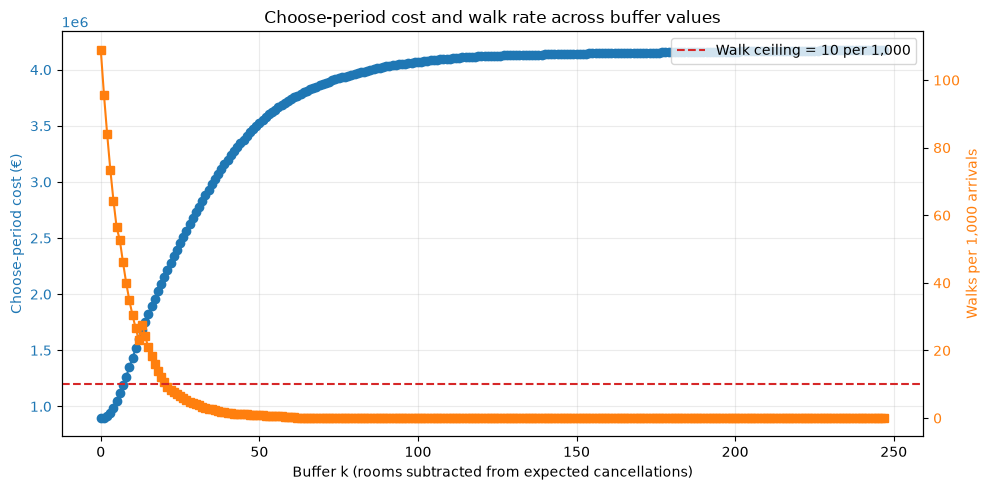

In [54]:
# For each buffer, show its cheapest candidate and that candidate's walk rate.
buffer_summary = (
    tuning_table.sort_values("Cost (EUR)")
    .groupby("Buffer", as_index=False)
    .first()
    .sort_values("Buffer")
)

fig, ax_cost = plt.subplots(figsize=(10, 5))
ax_cost.plot(buffer_summary["Buffer"], buffer_summary["Cost (EUR)"], marker="o", color="tab:blue")
ax_cost.set_xlabel("Buffer k (rooms subtracted from expected cancellations)")
ax_cost.set_ylabel("Choose-period cost (€)", color="tab:blue")
ax_cost.tick_params(axis="y", labelcolor="tab:blue")
ax_cost.grid(True, alpha=0.25)

ax_walks = ax_cost.twinx()
ax_walks.plot(buffer_summary["Buffer"], buffer_summary["Walks per 1,000"], marker="s", color="tab:orange")
ax_walks.axhline(10, color="tab:red", linestyle="--", label="Walk ceiling = 10 per 1,000")
ax_walks.set_ylabel("Walks per 1,000 arrivals", color="tab:orange")
ax_walks.tick_params(axis="y", labelcolor="tab:orange")
ax_walks.legend(loc="upper right")

plt.title("Choose-period cost and walk rate across buffer values")
plt.tight_layout()
plt.show()
